In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from tabular_study import clean_diagnose, one_hot_encode

In [3]:
dataset_path = "/data/mvillota/Datasets/Datasets/Processed/Oslo_viability/original.xlsx"
df = pd.read_excel(dataset_path, sheet_name="Morula_Blast_nov")

In [4]:
df['Fetal Heart Beat']= df['Fetal Heart Beat'].fillna(0)
df.loc[df['Fetal Heart Beat'] == 'mi', 'Fetal Heart Beat'] = None

## Preprocessing 

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3387 entries, 0 to 3386
Data columns (total 77 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   OPU_ID_Number (corresponds to treatment id) fripro  3350 non-null   float64
 1   Unnamed: 1                                          3387 non-null   object 
 2   Unnamed: 2                                          474 non-null    object 
 3   Embryo_id                                           3387 non-null   int64  
 4   Selection                                           3386 non-null   object 
 5   HCG Test                                            470 non-null    object 
 6   DET/TET                                             20 non-null     object 
 7   number of oocytes                                   464 non-null    object 
 8   IVF/ICSI                                            465 non-null    object 
 9

In [6]:
implantation = {
    'mi': None,
    'hcg testpositiv': 1,
    'pos': 1,
    'positiv': 1,
    'biokjemisk': 1,       
    'neg': 0,
    'negativ': 0,
    'negative': 0,
    'negativ (står positiv i lf uten mer informasjon, men neg. i sys.x.)': 0
}
df['HCG Test'] = df['HCG Test'].map(implantation)

In [7]:
df.dropna(subset=["HCG Test"], inplace=True)
df.reset_index(drop=True, inplace=True)

In [8]:
drop_column = ['OPU_ID_Number (corresponds to treatment id) fripro', 'Unnamed: 1', 'Unnamed: 2', 'Embryo_id','Unnamed: 11','Gestational Sacs', 
               'sex', 'week', 'lenght', 'weight','Unnamed: 15', 'End Time', 'Fertilization', 'Runs', 'Slide Description', 'Slide ID', 'Start Time', 
               'Transferred','tPB2', 'tPNa', 'tPNf', 'End Time', 'Fertilization', 'Runs', 'Slide Description', 'Slide ID', 'Start Time','Well', 
               'Well key', 'Unnamed: 76','Selection', 'DET/TET','Fragmentation - Time', 'Irregular Division - Time','Multi Nucleation - Time' ,
               'Pronuclei - Time', 'Inner Cell Mass - Time', 'Trophectoderm Evaluation - Time','USRVAR_1_Multinucleation - Time', 'USRVAR_2_Unormal oocytt - Time', 
               'USRVAR_3_DUC - Time', 'USRVAR_4_Reversert  - Time', 'USRVAR_5_Early cleavage - Time','number of oocytes',
               ]
df = df.drop(columns=drop_column)

In [9]:
for column in df.columns:
    print(f"{column}: {df[column].isna().sum()} nan values")

HCG Test: 0 nan values
IVF/ICSI: 5 nan values
Age: 5 nan values
Age_mann: 5 nan values
Diagnose: 6 nan values
smoke: 25 nan values
snus: 26 nan values
Abortion Comment: 422 nan values
Fetal Heart Beat: 3 nan values
complications: 434 nan values
t2: 6 nan values
t3: 7 nan values
t4: 7 nan values
t5: 9 nan values
t6: 9 nan values
t7: 13 nan values
t8: 36 nan values
t9+: 36 nan values
tSC: 211 nan values
tM: 22 nan values
tSB: 107 nan values
tB: 203 nan values
tEB: 325 nan values
tHB: 464 nan values
Blastomere Size - Time: 238 nan values
Blastomere Size - Value: 238 nan values
Fragmentation - Value: 34 nan values
Irregular Division - Value: 466 nan values
Multi Nucleation - Value: 376 nan values
Nuclei - Time: 40 nan values
Nuclei - Value: 40 nan values
Pronuclei - Value: 152 nan values
Inner Cell Mass - Value: 292 nan values
Trophectoderm Evaluation - Value: 290 nan values
USRVAR_1_Multinucleation - Value: 361 nan values
USRVAR_2_Unormal oocytt - Value: 455 nan values
USRVAR_3_DUC - Valu

In [10]:
columns_drop = ['Abortion Comment', 'complications', 'tEB','tHB', 'Irregular Division - Value', 'IVF/ICSI',
                'USRVAR_1_Multinucleation - Value',  'USRVAR_2_Unormal oocytt - Value',  'USRVAR_3_DUC - Value',
                 'USRVAR_4_Reversert  - Value',  'USRVAR_5_Early cleavage - Value', 'Blastomere Size - Time', 'Nuclei - Time',
                'USRVAR_2_Unormal oocytt - Value','USRVAR_3_DUC - Value', 'USRVAR_4_Reversert  - Value', 'USRVAR_5_Early cleavage - Value']
df = df.drop(columns=columns_drop)

In [ ]:
smoke_map = {
    # --- No smoker ---
    '0': 0,
    '0': 0,
    'nei': 0,
    
    # --- Smokers ---
    '3': 1,
    '5': 1,
    '0-5/d': 1,
    '1-5': 1,
    '1 (0-5/d)': 1,
    '1 (ikke daglig)': 1,

    # --- Heavy Smokers ---
    '1-10/d': 2,
    '10/d': 2,
    '1 (6-15/d)': 2,
    '1 (1-10/d)': 2,
    
    # --- noise ---
    'mi': None  # Se convertirá en NaN en Pandas
}
df['smoke'] = df['smoke'].map(smoke_map)

In [12]:
snus_map = {
    # --- No snus (0) ---
    '0': 0,
    'nei': 0,
    
    # --- snus (1) ---
    '1': 1,
    '2': 1,
    '3': 1,
    '5': 1,
    '4-5pk/d': 1,
    '1 (en sjelden gang)': 1,  
    '1 (0-1d/v)': 1,
    '1-2 d/v': 1,
    '1(slutter)': 1,           
    
    # --- Noise ---
    'mi': None                 
}
df['snus'] = df['snus'].map(snus_map)

### Transform Diagnose into categorical one hot encoder.
we have seen that there is no effect. 

In [13]:
diagnose = [str(d).lower() for d in df["Diagnose"]]
list_diseases = clean_diagnose(diagnose)
df = one_hot_encode(df, list_diseases)
df.drop(columns=["Diagnose"], inplace=True)

In [14]:
# convert nan to 0 in smoke and snus columns
df['smoke'] = df['smoke'].fillna(0)
df['snus'] = df['snus'].fillna(0)

In [15]:
blastomeres_map = {'Uneven': 0, 'Even': 1}
df['Blastomere Size - Value'] = df['Blastomere Size - Value'].map(blastomeres_map)

In [16]:
quality = {'A': 0, 'B': 1, 'C': 2}
df['Inner Cell Mass - Value'] = df['Inner Cell Mass - Value'].map(quality)
df['Trophectoderm Evaluation - Value'] = df['Trophectoderm Evaluation - Value'].map(quality)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 466 entries, 0 to 465
Data columns (total 32 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   HCG Test                          466 non-null    float64
 1   Age                               461 non-null    float64
 2   Age_mann                          461 non-null    float64
 3   smoke                             466 non-null    float64
 4   snus                              466 non-null    float64
 5   Fetal Heart Beat                  463 non-null    object 
 6   t2                                460 non-null    float64
 7   t3                                459 non-null    float64
 8   t4                                459 non-null    float64
 9   t5                                457 non-null    float64
 10  t6                                457 non-null    float64
 11  t7                                453 non-null    float64
 12  t8      

### Study of the distribution

In [18]:
def boxplot_variable_by_group(group_var, variable):
    df_1 = df[df[group_var] == 1][variable].dropna()
    df_0 = df[df[group_var] == 0][variable].dropna()
    
    plt.boxplot([df_0, df_1], tick_labels=[f'{group_var} = 0', f'{group_var} = 1'])
    plt.title(f'Boxplot of {variable} by {group_var} Result')
    plt.ylabel(variable)
    plt.show()

In [19]:
def histogram_variable_by_group(group_var, variable):
    df_1 = df[df[group_var] == 1][variable].dropna()
    df_0 = df[df[group_var] == 0][variable].dropna()
    x_values = sorted(set(df_0) | set(df_1))
    
    plt.hist(df_0, alpha=0.5, label=f'{group_var} = 0')
    plt.hist(df_1, alpha=0.5, label=f'{group_var} = 1')
    plt.title(f'Histogram of {variable} by {group_var} Result')
    plt.xlabel(variable)
    plt.ylabel('Frequency')
    plt.xticks(x_values)
    plt.legend()
    plt.show()

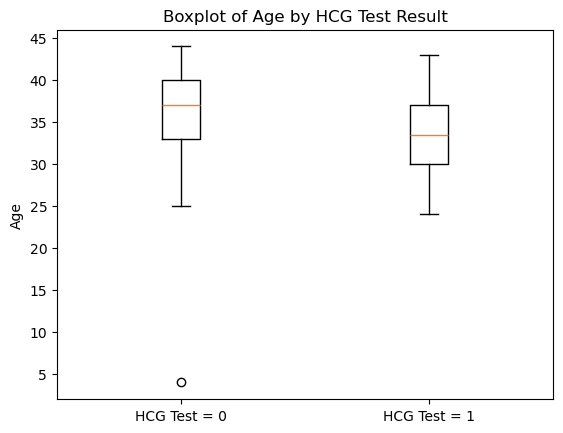

In [20]:
boxplot_variable_by_group('HCG Test', 'Age')

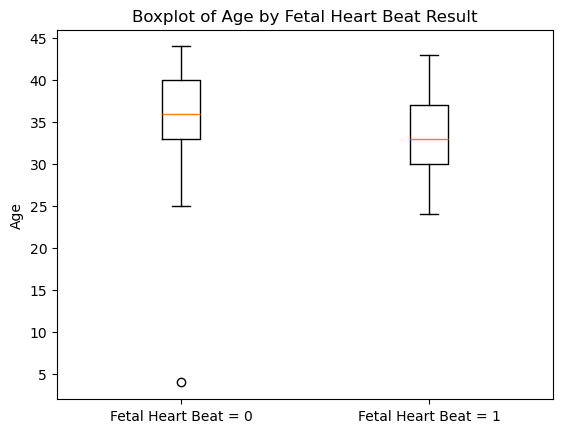

In [21]:
boxplot_variable_by_group('Fetal Heart Beat', 'Age')

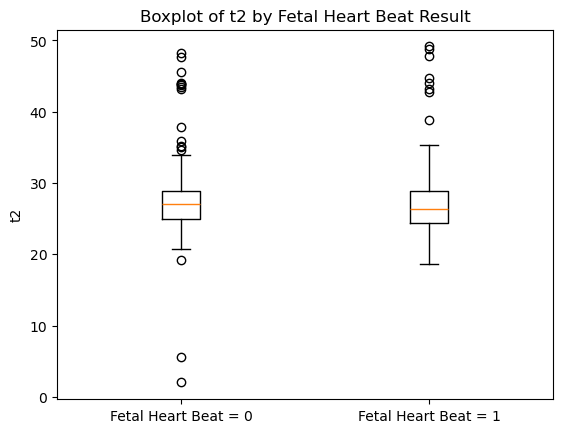

In [22]:
boxplot_variable_by_group('Fetal Heart Beat','t2')

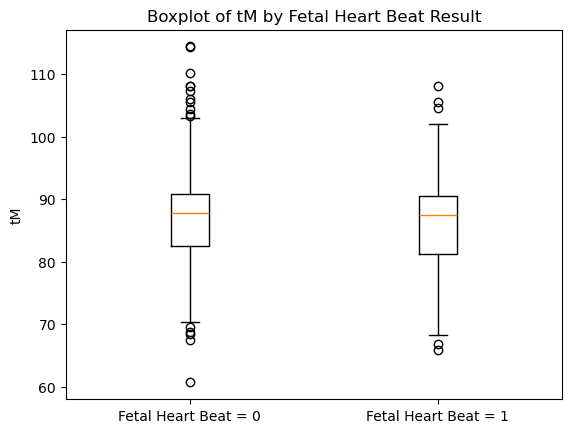

In [23]:
boxplot_variable_by_group('Fetal Heart Beat','tM')

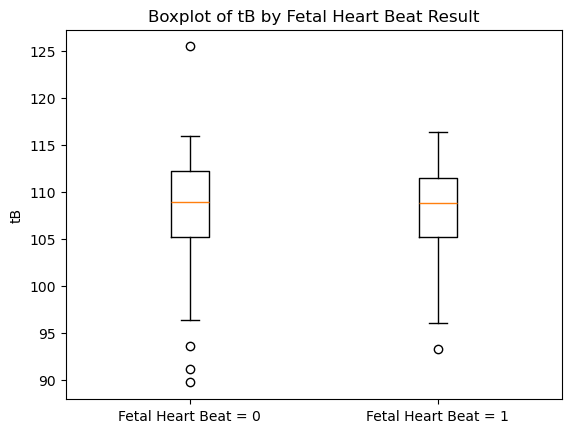

In [24]:
boxplot_variable_by_group('Fetal Heart Beat','tB')

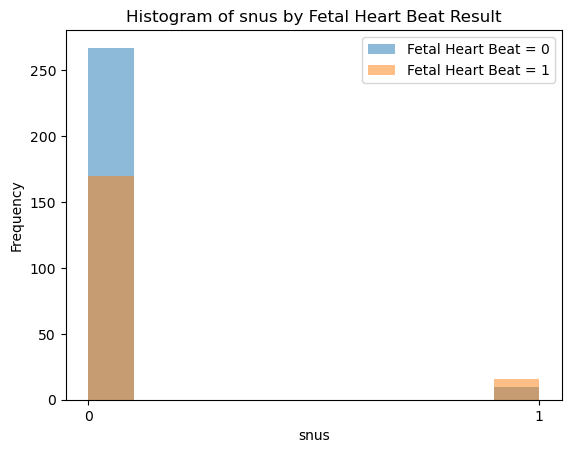

In [25]:
histogram_variable_by_group('Fetal Heart Beat', 'snus')

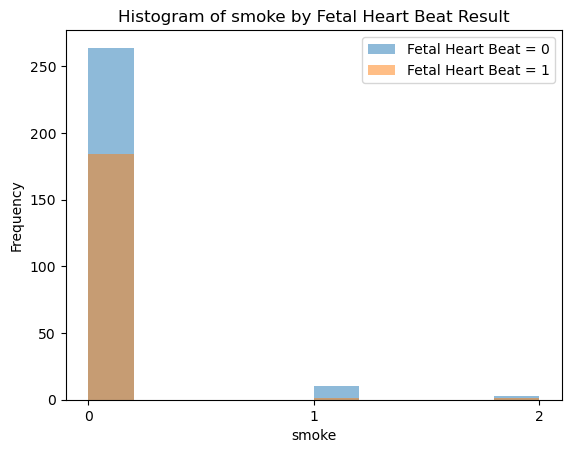

In [26]:
histogram_variable_by_group('Fetal Heart Beat', 'smoke')

In [27]:
df

,HCG Test,Age,Age_mann,smoke,snus,Fetal Heart Beat,t2,t3,t4,t5,...,Pronuclei - Value,Inner Cell Mass - Value,Trophectoderm Evaluation - Value,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor
0,0.0,34.0,29.0,0.0,0.0,0,24.658279,35.660900,37.661109,46.328552,...,2.0,NaN,NaN,0,0,0,0,0,0,1
1,1.0,34.0,41.0,0.0,0.0,0,28.102616,39.605694,40.356124,54.110138,...,2.0,NaN,NaN,0,0,0,0,0,0,1
2,0.0,33.0,34.0,0.0,0.0,0,27.856372,37.191602,37.191602,52.673399,...,NaN,NaN,NaN,0,0,1,0,0,0,0
3,0.0,33.0,35.0,0.0,0.0,0,23.765134,34.517857,34.517857,46.186794,...,2.0,NaN,NaN,0,0,0,1,0,0,0
4,1.0,29.0,30.0,0.0,0.0,1,26.614551,36.870546,36.870546,47.873351,...,2.0,NaN,NaN,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
461,1.0,38.0,38.0,0.0,0.0,1,32.536200,42.809855,45.261646,57.754240,...,NaN,NaN,NaN,0,0,0,0,0,0,1
462,1.0,35.0,36.0,0.0,0.0,0,30.774546,42.028888,42.028888,56.838670,...,2.0,NaN,NaN,0,0,0,1,0,0,0
463,0.0,39.0,37.0,0.0,0.0,0,29.046877,34.048488,42.052467,42.052467,...,2.0,NaN,NaN,0,0,0,1,0,0,0
464,0.0,41.0,38.0,0.0,0.0,0,NaN,NaN,NaN,NaN,...,NaN,1.0,NaN,0,0,0,0,1,0,1


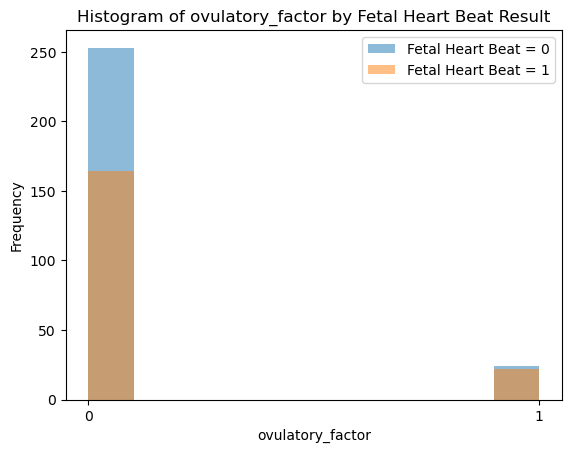

In [28]:
histogram_variable_by_group('Fetal Heart Beat', 'ovulatory_factor')

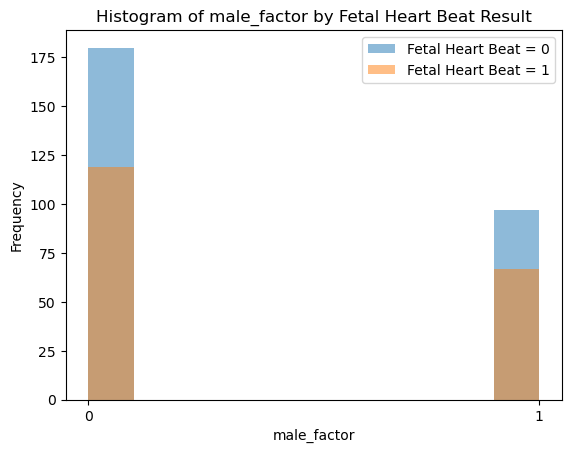

In [29]:
histogram_variable_by_group('Fetal Heart Beat', 'male_factor')

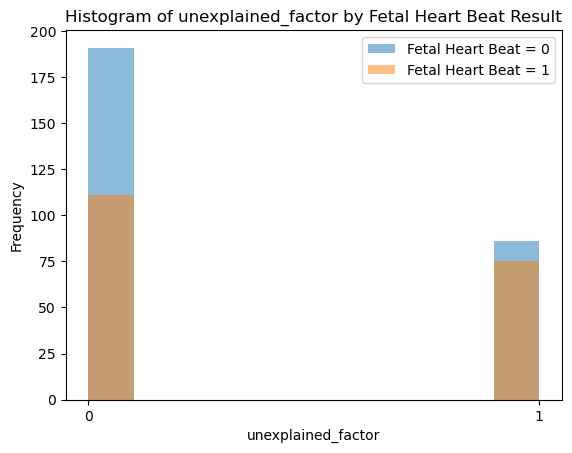

In [30]:
histogram_variable_by_group('Fetal Heart Beat', 'unexplained_factor')

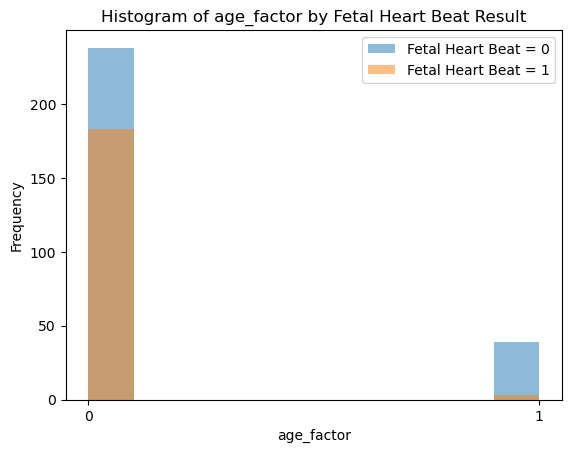

In [31]:
histogram_variable_by_group('Fetal Heart Beat', 'age_factor')

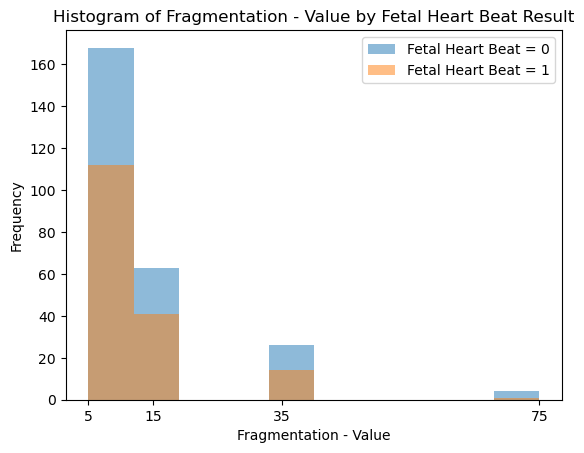

In [32]:
histogram_variable_by_group('Fetal Heart Beat', 'Fragmentation - Value')

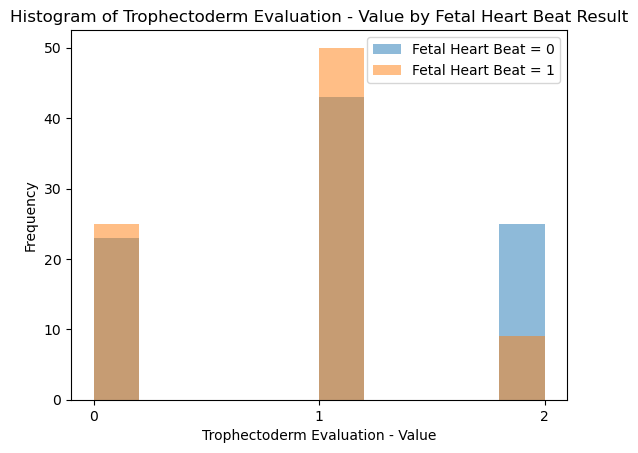

In [33]:
histogram_variable_by_group('Fetal Heart Beat', 'Trophectoderm Evaluation - Value')

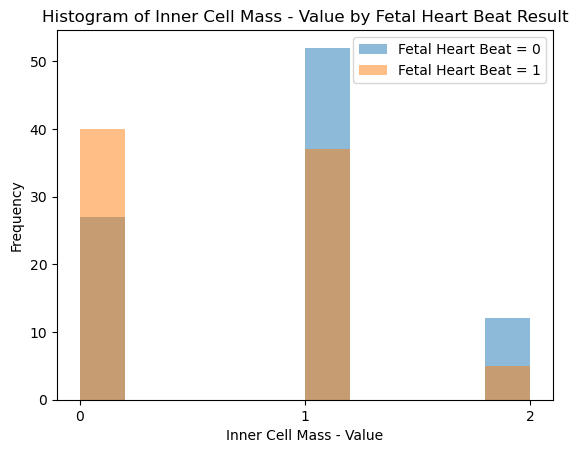

In [34]:
histogram_variable_by_group('Fetal Heart Beat', 'Inner Cell Mass - Value')

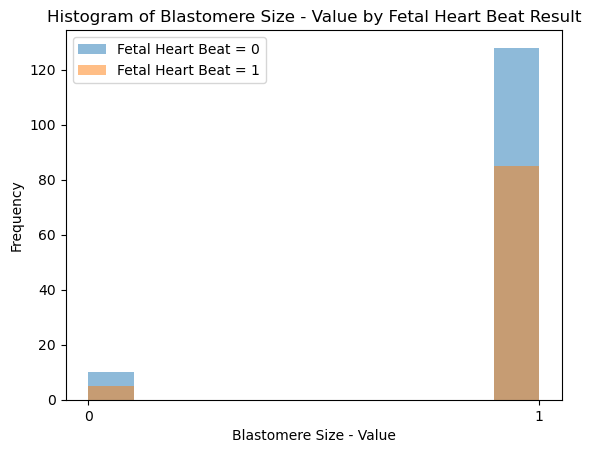

In [35]:
histogram_variable_by_group('Fetal Heart Beat', 'Blastomere Size - Value')

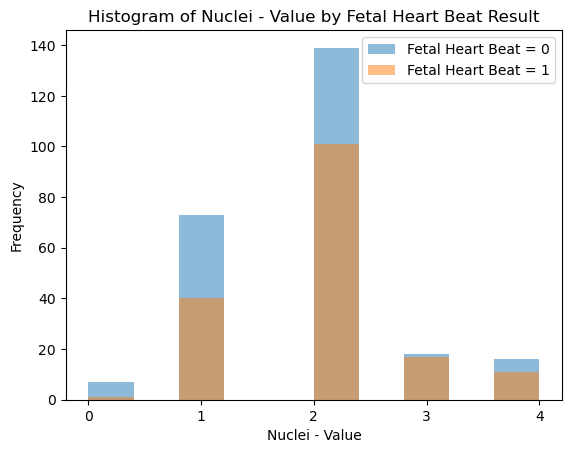

In [36]:
histogram_variable_by_group('Fetal Heart Beat', 'Nuclei - Value')

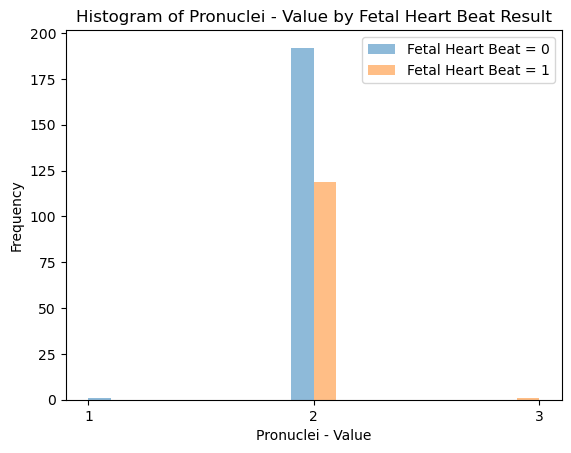

In [37]:
histogram_variable_by_group('Fetal Heart Beat', 'Pronuclei - Value')

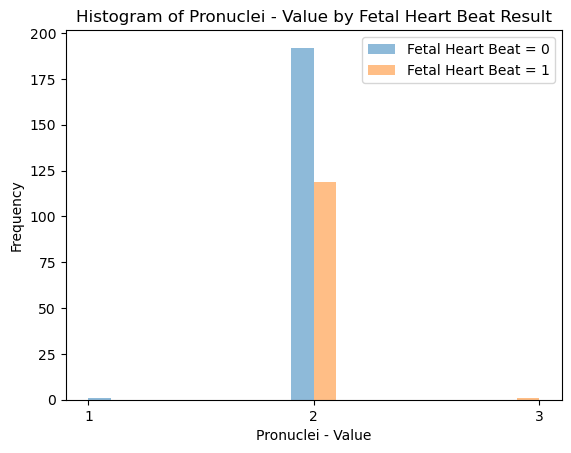

In [38]:
histogram_variable_by_group('Fetal Heart Beat', 'Pronuclei - Value')

### cleaning

In [39]:
for row in df.itertuples():
    if pd.isna(row._asdict()['t2']):
        print(row._asdict())
        df = df.drop(index=row.Index, inplace=False)
df = df.reset_index(drop=True)

{'Index': 141, '_1': 0.0, 'Age': nan, 'Age_mann': nan, 'smoke': 0.0, 'snus': 0.0, '_6': 0, 't2': nan, 't3': nan, 't4': nan, 't5': nan, 't6': nan, 't7': nan, 't8': nan, '_14': nan, 'tSC': nan, 'tM': nan, 'tSB': nan, 'tB': nan, '_19': nan, '_20': nan, '_21': nan, '_22': nan, '_23': nan, '_24': nan, '_25': nan, 'ovulatory_factor': 0, 'tubal_factor': 0, 'endometriosis_factor': 0, 'male_factor': 0, 'age_factor': 0, 'uterine_factor': 0, 'unexplained_factor': 0}
{'Index': 145, '_1': 1.0, 'Age': 39.0, 'Age_mann': 42.0, 'smoke': 0.0, 'snus': 0.0, '_6': 1, 't2': nan, 't3': nan, 't4': nan, 't5': nan, 't6': nan, 't7': nan, 't8': nan, '_14': nan, 'tSC': nan, 'tM': 92.30279889, 'tSB': 94.40545278, 'tB': 101.64802139, '_19': nan, '_20': nan, '_21': nan, '_22': nan, '_23': nan, '_24': nan, '_25': nan, 'ovulatory_factor': 0, 'tubal_factor': 0, 'endometriosis_factor': 0, 'male_factor': 1, 'age_factor': 0, 'uterine_factor': 0, 'unexplained_factor': 0}
{'Index': 365, '_1': 0.0, 'Age': 43.0, 'Age_mann': 47

In [40]:
df['Fragmentation - Value'] = df['Fragmentation - Value'].fillna(0)

In [41]:
df

,HCG Test,Age,Age_mann,smoke,snus,Fetal Heart Beat,t2,t3,t4,t5,...,Pronuclei - Value,Inner Cell Mass - Value,Trophectoderm Evaluation - Value,ovulatory_factor,tubal_factor,endometriosis_factor,male_factor,age_factor,uterine_factor,unexplained_factor
0,0.0,34.0,29.0,0.0,0.0,0,24.658279,35.660900,37.661109,46.328552,...,2.0,NaN,NaN,0,0,0,0,0,0,1
1,1.0,34.0,41.0,0.0,0.0,0,28.102616,39.605694,40.356124,54.110138,...,2.0,NaN,NaN,0,0,0,0,0,0,1
2,0.0,33.0,34.0,0.0,0.0,0,27.856372,37.191602,37.191602,52.673399,...,NaN,NaN,NaN,0,0,1,0,0,0,0
3,0.0,33.0,35.0,0.0,0.0,0,23.765134,34.517857,34.517857,46.186794,...,2.0,NaN,NaN,0,0,0,1,0,0,0
4,1.0,29.0,30.0,0.0,0.0,1,26.614551,36.870546,36.870546,47.873351,...,2.0,NaN,NaN,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
455,0.0,41.0,38.0,0.0,0.0,0,27.339983,38.435067,39.602701,51.860959,...,2.0,NaN,NaN,0,0,0,1,0,0,0
456,1.0,38.0,38.0,0.0,0.0,1,32.536200,42.809855,45.261646,57.754240,...,NaN,NaN,NaN,0,0,0,0,0,0,1
457,1.0,35.0,36.0,0.0,0.0,0,30.774546,42.028888,42.028888,56.838670,...,2.0,NaN,NaN,0,0,0,1,0,0,0
458,0.0,39.0,37.0,0.0,0.0,0,29.046877,34.048488,42.052467,42.052467,...,2.0,NaN,NaN,0,0,0,1,0,0,0


In [42]:
df = df.drop(columns=['tSB', 'tB', 'Blastomere Size - Value', 'Multi Nucleation - Value', 'Nuclei - Value', 
                      'Pronuclei - Value', 'Inner Cell Mass - Value', 'Trophectoderm Evaluation - Value', 'tSC'])
df.reset_index(inplace=True)

In [43]:
for index,row in df.iterrows():
    if row.isna().sum() > 5:
        print(row)
df.reset_index(inplace=True)

index                           16
HCG Test                       0.0
Age                           38.0
Age_mann                      39.0
smoke                          0.0
snus                           0.0
Fetal Heart Beat                 0
t2                       24.471947
t3                             NaN
t4                             NaN
t5                             NaN
t6                             NaN
t7                             NaN
t8                             NaN
t9+                       67.27478
tM                       78.823118
Fragmentation - Value         35.0
ovulatory_factor                 0
tubal_factor                     0
endometriosis_factor             0
male_factor                      1
age_factor                       0
uterine_factor                   0
unexplained_factor               0
Name: 16, dtype: object
index                           68
HCG Test                       0.0
Age                           27.0
Age_mann                      3

In [44]:
target_columns = df.loc[:, 't2':'tM']

filled_chunk = (target_columns.interpolate(axis=1)
                              .bfill(axis=1)
                              .ffill(axis=1)
                              .infer_objects(copy=False))

df.loc[:, 't2':'tM'] = filled_chunk

In [45]:
df.isnull().sum()

level_0                  0
index                    0
HCG Test                 0
Age                      4
Age_mann                 4
smoke                    0
snus                     0
Fetal Heart Beat         3
t2                       0
t3                       0
t4                       0
t5                       0
t6                       0
t7                       0
t8                       0
t9+                      0
tM                       0
Fragmentation - Value    0
ovulatory_factor         0
tubal_factor             0
endometriosis_factor     0
male_factor              0
age_factor               0
uterine_factor           0
unexplained_factor       0
dtype: int64

In [46]:
def fill_mean(df, column):
    mean_value = df[column].mean()
    if str(df[column].dtype).startswith('Int') or str(df[column].dtype).startswith('int'):
        mean_value = round(mean_value)
    df[column] = df[column].fillna(mean_value)
    return df

In [47]:
for column in ['Age', 'Age_mann']:
    df = fill_mean(df, column)

In [48]:
df['cc2'] = df['t4'] - df['t2']
df['cc3'] = df['t6'] - df['t3']
df['s2']  = df['t5'] - df['t3']

## Machine learning

In [49]:
import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score

# Importing the expanded model suite
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from tabpfn import TabPFNClassifier

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.model_selection import train_test_split

In [50]:
df.dropna(subset=['Fetal Heart Beat'], inplace=True)

In [51]:
X = df.drop(columns=['Fetal Heart Beat', 'HCG Test', 'level_0', 'index'])
y = df['Fetal Heart Beat']

In [52]:
# Split the dataset: 80% for training and 20% for testing the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      # 20% for testing (94 patients)
    random_state=42,    # Seed to ensure the experiment is reproducible
    stratify=y          # Maintains the same proportion of hCG successes/failures in both sets
)

print(f"Patients for training: {X_train.shape[0]}")
print(f"Patients for testing: {X_test.shape[0]}")

Patients for training: 365
Patients for testing: 92


In [53]:
y_train = list(y_train)
y_test = list(y_test)

In [54]:
classifiers = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'classifier__C': [0.01, 0.1, 1.0, 10.0],
            'classifier__penalty': ['l2']
        }
    },
    'DecisionTree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'classifier__criterion': ['gini', 'entropy'],
            'classifier__max_depth': [None, 4, 6, 8, 12],
            'classifier__min_samples_split': [2, 5, 10]
        }
    },
    'SVC': {
        'model': SVC(probability=True, random_state=42), # probability=True is needed for ROC-AUC / prediction thresholds
        'params': {
            'classifier__C': [0.1, 1.0, 10.0],
            'classifier__kernel': ['linear', 'rbf'],
            'classifier__gamma': ['scale', 'auto']
        }
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'classifier__n_neighbors': [3, 5, 7, 11, 15],
            'classifier__weights': ['uniform', 'distance'],
            'classifier__metric': ['euclidean', 'manhattan']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__min_samples_split': [2, 5]
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__criterion': ['gini', 'entropy']
        }
    },
    'GradientBoosting': {
        'model': HistGradientBoostingClassifier(random_state=42),
        'params': {
            'classifier__learning_rate': [0.01, 0.05, 0.1],
            'classifier__max_iter': [100, 150],
            'classifier__max_depth': [3, 5, 7]
        }
    },
    'TabPFN': {
        'model': TabPFNClassifier(ignore_pretraining_limits=True),
        'params': {}
    }
}

In [55]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {}
best_score = 0
best_pipeline = None
best_model_name = ""

print("--- Starting Extensive Cross-Validation Grid Search ---")
for name, config in classifiers.items():
    # Constructing the structural pipeline for each model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', config['model'])
    ])
    
    # Running GridSearch optimizing for ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config['params'],
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train, y_train)
    print(f"🔹 {name:<20} -> Best CV ROC-AUC: {grid_search.best_score_:.4f}")
    models[name] = grid_search
    
    # Track down the absolute king of performance
    if grid_search.best_score_ > best_score:
        best_score = grid_search.best_score_
        best_pipeline = grid_search.best_estimator_
        best_model_name = name

--- Starting Extensive Cross-Validation Grid Search ---


🔹 LogisticRegression   -> Best CV ROC-AUC: 0.6071
🔹 DecisionTree         -> Best CV ROC-AUC: 0.5548
🔹 SVC                  -> Best CV ROC-AUC: 0.5907
🔹 KNN                  -> Best CV ROC-AUC: 0.5697
🔹 RandomForest         -> Best CV ROC-AUC: 0.6059
🔹 ExtraTrees           -> Best CV ROC-AUC: 0.6133
🔹 GradientBoosting     -> Best CV ROC-AUC: 0.6061
🔹 TabPFN               -> Best CV ROC-AUC: 0.6122


In [56]:
print(f"\n WINNER MODEL: {best_model_name} (CV ROC-AUC: {best_score:.4f})")
print(best_pipeline)


 WINNER MODEL: ExtraTrees (CV ROC-AUC: 0.6133)
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 ExtraTreesClassifier(max_depth=5, n_estimators=200,
                                      random_state=42))])


In [57]:
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))


--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.6796

                 precision    recall  f1-score   support

FHB Failure (0)       0.62      1.00      0.76        55
FHB Success (1)       1.00      0.08      0.15        37

       accuracy                           0.63        92
      macro avg       0.81      0.54      0.46        92
   weighted avg       0.77      0.63      0.52        92



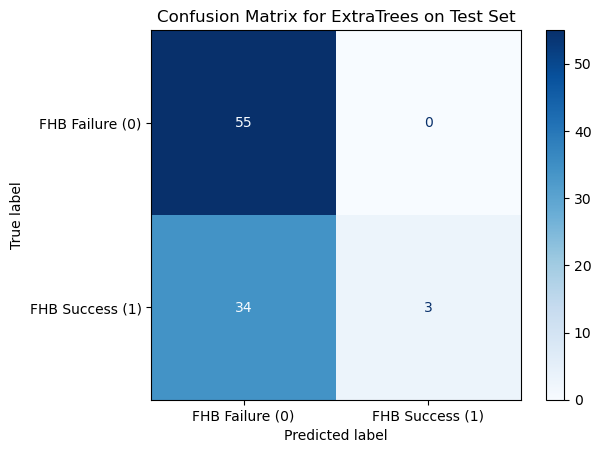

In [58]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

In [59]:
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
for model in models:
    best_pipeline = models[model].best_estimator_
    y_pred = best_pipeline.predict(X_test)
    y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]
    print(f"{model}: {roc_auc_score(y_test, y_pred_proba):.4f} ")


--- Final Test Set Evaluation (Unseen Patients) ---
LogisticRegression: 0.7351 
DecisionTree: 0.5663 
SVC: 0.6752 
KNN: 0.6140 
RandomForest: 0.6366 
ExtraTrees: 0.6796 
GradientBoosting: 0.6447 
TabPFN: 0.7251 


### TabPFN

In [60]:
best_pipeline = models['TabPFN'].best_estimator_
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))


--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.7251

                 precision    recall  f1-score   support

FHB Failure (0)       0.69      0.93      0.79        55
FHB Success (1)       0.78      0.38      0.51        37

       accuracy                           0.71        92
      macro avg       0.73      0.65      0.65        92
   weighted avg       0.72      0.71      0.68        92



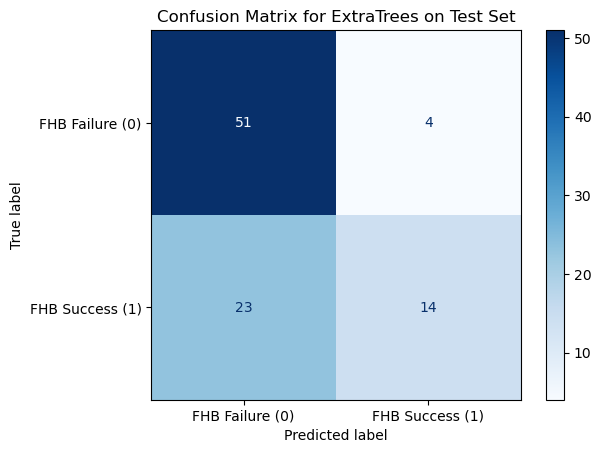

In [61]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

### LogisticRegression

In [62]:
best_pipeline = models['LogisticRegression'].best_estimator_
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))


--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.7351

                 precision    recall  f1-score   support

FHB Failure (0)       0.64      1.00      0.78        55
FHB Success (1)       1.00      0.16      0.28        37

       accuracy                           0.66        92
      macro avg       0.82      0.58      0.53        92
   weighted avg       0.78      0.66      0.58        92



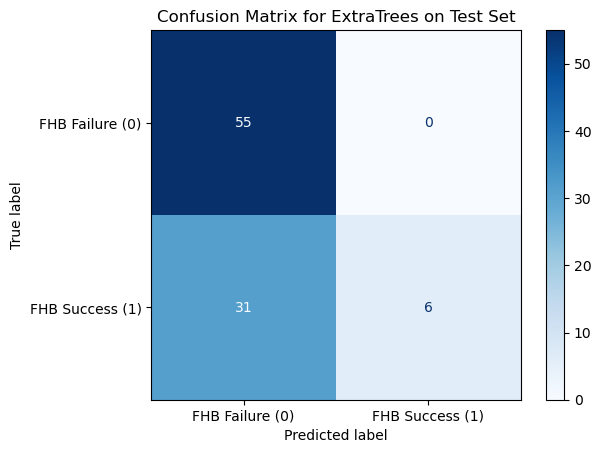

In [63]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

In [64]:
weights = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': best_pipeline.named_steps['classifier'].coef_[0] if hasattr(best_pipeline.named_steps['classifier'], 'coef_') else None
})

Text(0, 0.5, 'Coefficient Value')

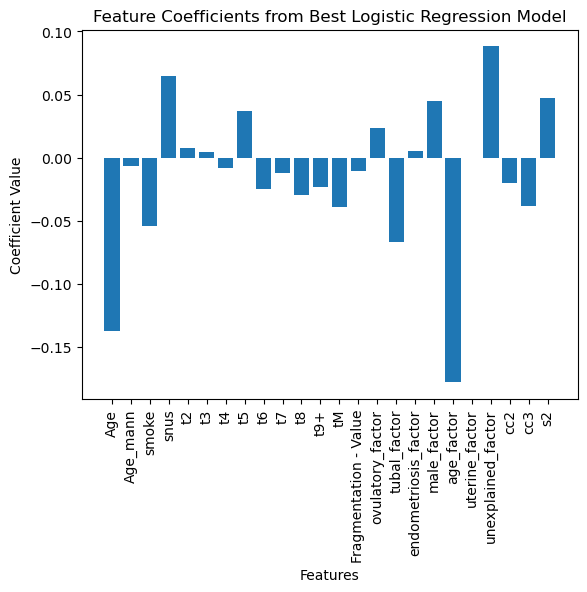

In [65]:
plt.bar(weights['Feature'], weights['Coefficient'])
plt.xticks(rotation=90)
plt.title('Feature Coefficients from Best Logistic Regression Model')
plt.xlabel('Features')
plt.ylabel('Coefficient Value')

### Ensemble

In [97]:
from sklearn.ensemble import VotingClassifier

eclf = VotingClassifier(
    estimators=[(m, models[m].best_estimator_) for m in ['LogisticRegression', 'TabPFN']],
    voting='soft'
)

eclf.fit(X_train, y_train)
y_pred = eclf.predict(X_test)
y_proba = eclf.predict_proba(X_test)[:, 1]

In [98]:
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['FHB Failure (0)', 'FHB Success (1)']))

Test Set ROC-AUC Score: 0.7405

                 precision    recall  f1-score   support

FHB Failure (0)       0.67      0.98      0.79        55
FHB Success (1)       0.91      0.27      0.42        37

       accuracy                           0.70        92
      macro avg       0.79      0.63      0.61        92
   weighted avg       0.76      0.70      0.64        92



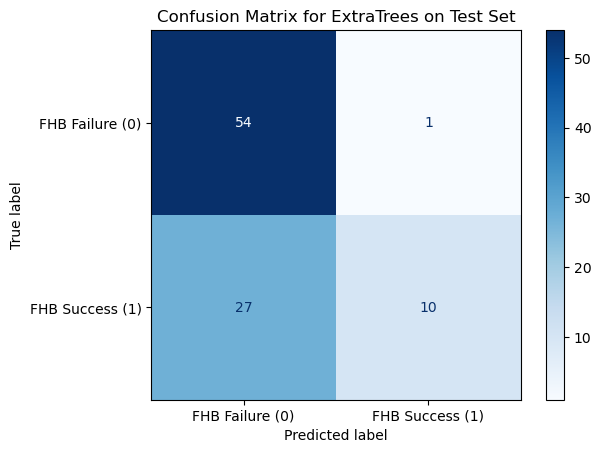

In [99]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

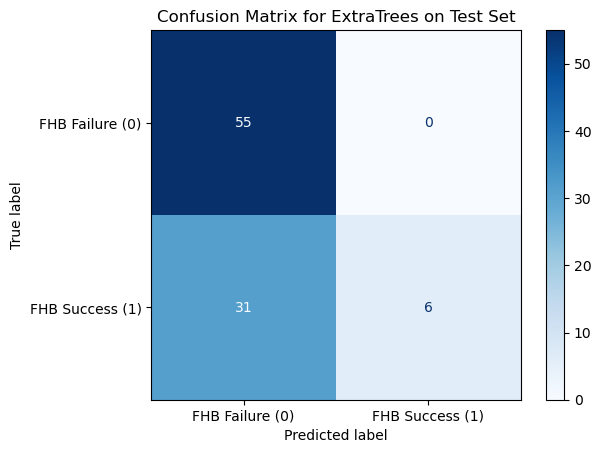

In [ ]:
eclf = VotingClassifier(
    estimators=[(m, models[m].best_estimator_) for m in ['LogisticRegression', 'TabPFN']],
    voting='hard'
)

eclf.fit(X_train, y_train)
y_pred = eclf.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FHB Failure (0)', 'FHB Success (1)'])
disp.plot(cmap=plt.cm.Blues)
plt.title(f'Confusion Matrix for {best_model_name} on Test Set')
plt.show()

### Algoritmo ASEBIR

In [104]:
df_times = df[['t2', 'cc2', 'cc3', 's2', 'Fetal Heart Beat']].dropna()

In [121]:
float(np.mean(df_times.loc[df_times['cc2'] <= 5, 'Fetal Heart Beat']))*100

41.66666666666667

In [129]:
df_cc2_5 = df_times.loc[df_times['cc2'] > 5]
float(np.mean(df_cc2_5.loc[df_cc2_5['s2'] >= 5, 'Fetal Heart Beat']))*100

41.14713216957606

In [138]:
df_s2 = df_cc2_5[df_cc2_5['s2'] < 5]
df_cc3 = df_s2[(df_s2['cc3'] > 11) & (df_s2['cc3'] < 15)]

In [140]:
df_cc3.loc[(df_cc3['t2'] < 24) & (df_cc3['t2'] > 25), 'Fetal Heart Beat']

Series([], Name: Fetal Heart Beat, dtype: object)

In [68]:
X = df[['t2', 'cc2', 'cc3', 's2']]
y = df['Fetal Heart Beat']

In [69]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2,      # 20% for testing (94 patients)
    random_state=42,    # Seed to ensure the experiment is reproducible
    stratify=y          # Maintains the same proportion of hCG successes/failures in both sets
)

print(f"Patients for training: {X_train.shape[0]}")
print(f"Patients for testing: {X_test.shape[0]}")
y_train = list(y_train)
y_test = list(y_test)

Patients for training: 365
Patients for testing: 92


In [70]:
# 1. Define an extensive dictionary of models and hyperparameter grids
classifiers = {
    'LogisticRegression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'classifier__C': [0.01, 0.1, 1.0, 10.0],
            'classifier__penalty': ['l2']
        }
    },
    'DecisionTree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'classifier__criterion': ['gini', 'entropy'],
            'classifier__max_depth': [None, 4, 6, 8, 12],
            'classifier__min_samples_split': [2, 5, 10]
        }
    },
    'SVC': {
        'model': SVC(probability=True, random_state=42), # probability=True is needed for ROC-AUC / prediction thresholds
        'params': {
            'classifier__C': [0.1, 1.0, 10.0],
            'classifier__kernel': ['linear', 'rbf'],
            'classifier__gamma': ['scale', 'auto']
        }
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'classifier__n_neighbors': [3, 5, 7, 11, 15],
            'classifier__weights': ['uniform', 'distance'],
            'classifier__metric': ['euclidean', 'manhattan']
        }
    },
    'RandomForest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__min_samples_split': [2, 5]
        }
    },
    'ExtraTrees': {
        'model': ExtraTreesClassifier(random_state=42),
        'params': {
            'classifier__n_estimators': [100, 200],
            'classifier__max_depth': [None, 5, 10],
            'classifier__criterion': ['gini', 'entropy']
        }
    },
    'GradientBoosting': {
        'model': HistGradientBoostingClassifier(random_state=42),
        'params': {
            'classifier__learning_rate': [0.01, 0.05, 0.1],
            'classifier__max_iter': [100, 150],
            'classifier__max_depth': [3, 5, 7]
        }
    }
}

# 2. Setup Stratified 5-Fold Cross Validation
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

best_score = 0
best_pipeline = None
best_model_name = ""

print("--- Starting Extensive Cross-Validation Grid Search ---")
for name, config in classifiers.items():
    # Constructing the structural pipeline for each model
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', config['model'])
    ])
    
    # Running GridSearch optimizing for ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config['params'],
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=0
    )
    
    grid_search.fit(X_train, y_train)
    print(f"🔹 {name:<20} -> Best CV ROC-AUC: {grid_search.best_score_:.4f}")
    
    # Track down the absolute king of performance
    if grid_search.best_score_ > best_score:
        best_score = grid_search.best_score_
        best_pipeline = grid_search.best_estimator_
        best_model_name = name

print(f"\n WINNER MODEL: {best_model_name} (CV ROC-AUC: {best_score:.4f})")
print(best_pipeline)

# 3. Final Evaluation on Holdout Test Set
print("\n--- Final Test Set Evaluation (Unseen Patients) ---")
y_pred = best_pipeline.predict(X_test)
y_pred_proba = best_pipeline.predict_proba(X_test)[:, 1]

print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Implantation Failure (0)', 'Implantation Success (1)']))

--- Starting Extensive Cross-Validation Grid Search ---


🔹 LogisticRegression   -> Best CV ROC-AUC: 0.5094
🔹 DecisionTree         -> Best CV ROC-AUC: 0.5057
🔹 SVC                  -> Best CV ROC-AUC: 0.5595
🔹 KNN                  -> Best CV ROC-AUC: 0.5639
🔹 RandomForest         -> Best CV ROC-AUC: 0.5143
🔹 ExtraTrees           -> Best CV ROC-AUC: 0.5351
🔹 GradientBoosting     -> Best CV ROC-AUC: 0.5078

 WINNER MODEL: KNN (CV ROC-AUC: 0.5639)
Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier(metric='manhattan'))])

--- Final Test Set Evaluation (Unseen Patients) ---
Test Set ROC-AUC Score: 0.4808

                          precision    recall  f1-score   support

Implantation Failure (0)       0.57      0.75      0.65        55
Implantation Success (1)       0.30      0.16      0.21        37

                accuracy                           0.51        92
               macro avg       0.43      0.45      0.43        92
            weighted avg       0.46      0.51      0.47        92



In [ ]:
clf = DecisionTreeClassifier(random_state=42, max_depth=10, criterion='gini')
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.58      0.67      0.62        55
           1       0.36      0.27      0.31        37

    accuracy                           0.51        92
   macro avg       0.47      0.47      0.46        92
weighted avg       0.49      0.51      0.50        92



In [ ]:
# print decision tree rules
from sklearn.tree import export_text
tree_rules = export_text(clf, feature_names=list(X.columns))
print(tree_rules)

|--- cc3 <= 16.52
|   |--- t2 <= 25.44
|   |   |--- s2 <= 0.53
|   |   |   |--- class: 0
|   |   |--- s2 >  0.53
|   |   |   |--- cc2 <= 9.05
|   |   |   |   |--- cc2 <= 7.54
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- cc2 >  7.54
|   |   |   |   |   |--- class: 0
|   |   |   |--- cc2 >  9.05
|   |   |   |   |--- t2 <= 22.97
|   |   |   |   |   |--- cc2 <= 11.97
|   |   |   |   |   |   |--- cc3 <= 9.98
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- cc3 >  9.98
|   |   |   |   |   |   |   |--- t2 <= 22.73
|   |   |   |   |   |   |   |   |--- s2 <= 12.63
|   |   |   |   |   |   |   |   |   |--- cc3 <= 11.98
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |   |--- cc3 >  11.98
|   |   |   |   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |   |   |--- s2 >  12.63
|   |   |   |   |   |   |   |   |   |--- cc2 <= 11.33
|   |   |   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |   |   |

# Statistics Report

### Categorical variables
1. Smoking vs Implantation

    H_0: Smoking has no association with implantation success
    
    H_1: They are dependent

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from scipy.stats import fisher_exact

In [ ]:
implantation = {
    'hcg testpositiv': 1,
    'pos': 1,
    'positiv': 1,
    'biokjemisk': 1,       
    'neg': 0,
    'negativ': 0,
    'negative': 0,
    'negativ (står positiv i lf uten mer informasjon, men neg. i sys.x.)': 0
}
df['HCG Test'] = df['HCG Test'].map(implantation)

In [ ]:
def chi_statistics(contingency_table):
    chi2, p, dof, expected_frequencies = chi2_contingency(contingency_table)
    expected_df = pd.DataFrame(expected_frequencies, 
                           index=contingency_table.index, 
                           columns=contingency_table.columns)

    print("--- Expected Counts (If No Relationship Existed) ---")
    print(expected_df, "\n")
    print("--- Statistical Results ---")
    print(f"Chi-squared Statistic: {chi2:.4f}")
    print(f"Degrees of Freedom: {dof}")
    print(f"p-value: {p:.4e}") # Displays in scientific notation if very small

    # Evaluate p-value (Alpha = 0.05)
    alpha = 0.05
    if p < alpha:
        print(f"✅ Reject the Null Hypothesis (p < {alpha}).")
        print("There is a statistically significant association between the two variables.")
    else:
        print(f"❌ Fail to Reject the Null Hypothesis (p >= {alpha}).")
        print("There is no evidence of a significant association between the variables.")

In [ ]:
def fisher_statistics(contingency_table):
    odds_ratio, p_value = fisher_exact(contingency_table)

    print("--- Statistical Results ---")
    print(f"Odds Ratio (OR): {odds_ratio:.4f}")
    print(f"p-value: {p_value:.4f}")

    print("\n--- Clinical Interpretation ---")
    alpha = 0.05
    if p_value < alpha:
        print(f"✅ Reject $H_0$ (p < {alpha}). The association is statistically significant.")
        if odds_ratio < 1:
            print("Interpretation: The exposure factor (e.g., Smoking) is associated with LOWER odds of Implantation Success.")
        elif odds_ratio > 1:
            print("Interpretation: The exposure factor is associated with HIGHER odds of Implantation Success.")
    else:
        print(f"❌ Fail to Reject $H_0$ (p >= {alpha}).")
        print("No statistically significant association was found between the two variables.")

In [ ]:
def categorical_statistics(contingency_table):
    if (contingency_table < 5).any().any():
        print("⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.\n")
        fisher_statistics(contingency_table)
    else:
        chi_statistics(contingency_table)

In [ ]:
def var_categorical_statistics(df, variable, group_var='HCG Test'):
    contingency_table = pd.crosstab(df[variable], df[group_var])
    print(f"--- Contingency Table for {variable} vs {group_var} ---")
    print(contingency_table, "\n")
    categorical_statistics(contingency_table)

#### SMOKE and SNUS

In [ ]:
smoke_map = {
    # --- No smoker ---
    '0': 'No_smoker',
    '0': 'No_smoker',
    'nei': 'No_smoker',
    
    # --- Smokers ---
    '3': 'Smoker',
    '5': 'Smoker',
    '0-5/d': 'Smoker',
    '1-5': 'Smoker',
    '1 (0-5/d)': 'Smoker',
    '1 (ikke daglig)': 'Smoker',
    # --- Heavy Smokers ---
    '1-10/d': 'Heavy_Smoker',
    '10/d': 'Heavy_Smoker',
    '1 (6-15/d)': 'Heavy_Smoker',
    '1 (1-10/d)': 'Heavy_Smoker',
    
    
    # --- noise ---
    'mi': None  # Se convertirá en NaN en Pandas
}
df['smoke'] = df['smoke'].map(smoke_map)

In [ ]:
df1 = df.dropna(subset=['smoke', 'HCG Test'])
var_categorical_statistics(df1, 'smoke', 'HCG Test')

--- Contingency Table for smoke vs HCG Test ---
HCG Test      0.0  1.0
smoke                 
Heavy_Smoker    3    1
No_smoker     109  148
Smoker          9    2 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0019
p-value: 0.0100

--- Clinical Interpretation ---
✅ Reject $H_0$ (p < 0.05). The association is statistically significant.
Interpretation: The exposure factor (e.g., Smoking) is associated with LOWER odds of Implantation Success.


In [ ]:
df1 = df.dropna(subset=['smoke', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'smoke', 'Fetal Heart Beat')

--- Contingency Table for smoke vs Fetal Heart Beat ---
Fetal Heart Beat    0    1
smoke                     
Heavy_Smoker        3    1
No_smoker         136  121
Smoker             10    1 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0031
p-value: 0.0188

--- Clinical Interpretation ---
✅ Reject $H_0$ (p < 0.05). The association is statistically significant.
Interpretation: The exposure factor (e.g., Smoking) is associated with LOWER odds of Implantation Success.


In [ ]:
snus_map = {
    # --- No snus (0) ---
    '0': 'No_snus',
    'nei': 'No_snus',
    
    # --- snus (1) ---
    '1': 'Snus',
    '2': 'Snus',
    '3': 'Snus',
    '5': 'Snus',
    '4-5pk/d': 'Snus',
    '1 (en sjelden gang)': 'Snus',  
    '1 (0-1d/v)': 'Snus',
    '1-2 d/v': 'Snus',
    '1(slutter)': 'Snus',           
    
    # --- Noise ---
    'mi': None                 
}
df['snus'] = df['snus'].map(snus_map)

In [ ]:
df1 = df.dropna(subset=['snus', 'HCG Test'])
var_categorical_statistics(df1, 'snus', 'HCG Test')

--- Contingency Table for snus vs HCG Test ---
HCG Test  0.0  1.0
snus              
No_snus   112  136
Snus        9   17 

--- Expected Counts (If No Relationship Existed) ---
HCG Test         0.0         1.0
snus                            
No_snus   109.518248  138.481752
Snus       11.481752   14.518248 

--- Statistical Results ---
Chi-squared Statistic: 0.6768
Degrees of Freedom: 1
p-value: 4.1070e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


In [ ]:
df1 = df.dropna(subset=['snus', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'snus', 'Fetal Heart Beat')

--- Contingency Table for snus vs Fetal Heart Beat ---
Fetal Heart Beat    0    1
snus                      
No_snus           140  108
Snus               10   16 

--- Expected Counts (If No Relationship Existed) ---
Fetal Heart Beat           0           1
snus                                    
No_snus           135.766423  112.233577
Snus               14.233577   11.766423 

--- Statistical Results ---
Chi-squared Statistic: 2.3909
Degrees of Freedom: 1
p-value: 1.2204e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


#### QUALITY ICM and TE

In [ ]:
df1 = df.dropna(subset=['Inner Cell Mass - Value', 'HCG Test'])
var_categorical_statistics(df1, 'Inner Cell Mass - Value', 'HCG Test')

--- Contingency Table for Inner Cell Mass - Value vs HCG Test ---
HCG Test                 0.0  1.0
Inner Cell Mass - Value          
A                         22   45
B                         48   42
C                          9    8 

--- Expected Counts (If No Relationship Existed) ---
HCG Test                       0.0        1.0
Inner Cell Mass - Value                      
A                        30.419540  36.580460
B                        40.862069  49.137931
C                         7.718391   9.281609 

--- Statistical Results ---
Chi-squared Statistic: 6.9418
Degrees of Freedom: 2
p-value: 3.1089e-02
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant association between the two variables.


In [ ]:
df1 = df.dropna(subset=['Inner Cell Mass - Value', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'Inner Cell Mass - Value', 'Fetal Heart Beat')

--- Contingency Table for Inner Cell Mass - Value vs Fetal Heart Beat ---
Fetal Heart Beat          0   1
Inner Cell Mass - Value        
A                        28  40
B                        52  37
C                        13   5 

--- Expected Counts (If No Relationship Existed) ---
Fetal Heart Beat                 0          1
Inner Cell Mass - Value                      
A                        36.137143  31.862857
B                        47.297143  41.702857
C                         9.565714   8.434286 

--- Statistical Results ---
Chi-squared Statistic: 7.5397
Degrees of Freedom: 2
p-value: 2.3056e-02
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant association between the two variables.


In [ ]:
df1 = df.dropna(subset=['Trophectoderm Evaluation - Value', 'HCG Test'])
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'HCG Test')

--- Contingency Table for Trophectoderm Evaluation - Value vs HCG Test ---
HCG Test                          0.0  1.0
Trophectoderm Evaluation - Value          
A                                  18   30
B                                  40   54
C                                  21   13 

--- Expected Counts (If No Relationship Existed) ---
HCG Test                                0.0        1.0
Trophectoderm Evaluation - Value                      
A                                 21.545455  26.454545
B                                 42.193182  51.806818
C                                 15.261364  18.738636 

--- Statistical Results ---
Chi-squared Statistic: 5.1807
Degrees of Freedom: 2
p-value: 7.4992e-02
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


In [ ]:
df1 = df.dropna(subset=['Trophectoderm Evaluation - Value', 'Fetal Heart Beat'])
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'Fetal Heart Beat')

--- Contingency Table for Trophectoderm Evaluation - Value vs Fetal Heart Beat ---
Fetal Heart Beat                   0   1
Trophectoderm Evaluation - Value        
A                                 24  25
B                                 44  50
C                                 25   9 

--- Expected Counts (If No Relationship Existed) ---
Fetal Heart Beat                          0          1
Trophectoderm Evaluation - Value                      
A                                 25.745763  23.254237
B                                 49.389831  44.610169
C                                 17.864407  16.135593 

--- Statistical Results ---
Chi-squared Statistic: 7.4945
Degrees of Freedom: 2
p-value: 2.3582e-02
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant association between the two variables.


#### Blastomeres size

In [ ]:
group = 'HCG Test'
variable = 'Blastomere Size - Value'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table for Blastomere Size - Value vs HCG Test ---
HCG Test                 0.0  1.0
Blastomere Size - Value          
Even                     107  106
Uneven                     8    7 

--- Expected Counts (If No Relationship Existed) ---
HCG Test                        0.0         1.0
Blastomere Size - Value                        
Even                     107.434211  105.565789
Uneven                     7.565789    7.434211 

--- Statistical Results ---
Chi-squared Statistic: 0.0000
Degrees of Freedom: 1
p-value: 1.0000e+00
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


In [ ]:
group = 'Fetal Heart Beat'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)

--- Contingency Table for Blastomere Size - Value vs Fetal Heart Beat ---
Fetal Heart Beat           0   1
Blastomere Size - Value         
Even                     128  85
Uneven                    10   5 

--- Expected Counts (If No Relationship Existed) ---
Fetal Heart Beat                  0          1
Blastomere Size - Value                       
Even                     128.921053  84.078947
Uneven                     9.078947   5.921053 

--- Statistical Results ---
Chi-squared Statistic: 0.0530
Degrees of Freedom: 1
p-value: 8.1800e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


#### Fragmentation

In [ ]:
group = 'HCG Test'
variable = 'Fragmentation - Value'
df1 = df.dropna(subset=[variable, group])
var_categorical_statistics(df1, variable, group)


--- Contingency Table for Fragmentation - Value vs HCG Test ---
HCG Test               0.0  1.0
Fragmentation - Value          
5.0                    140  143
15.0                    55   49
35.0                    22   18
75.0                     3    2 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0028
p-value: 0.8327

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
contingency_table = pd.crosstab(df1['Fragmentation - Value'], df1['Fetal Heart Beat'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

Fetal Heart Beat         0    1
Fragmentation - Value          
5.0                    168  112
15.0                    63   41
35.0                    26   14
75.0                     4    1 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0029
p-value: 0.8427

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


#### diagnose

In [ ]:
diagnose = [str(d).lower() for d in df["Diagnose"]]
list_diseases = clean_diagnose(df, diseases)
one_hot_df = one_hot_encode(list_diseases, columns_study)
df = pd.concat([df, one_hot_df], axis=1)
df.drop(columns=["Diagnose"], inplace=True)

In [ ]:
df1 = df.dropna(subset=['female_factor', 'HCG Test'])
contingency_table = pd.crosstab(df1['female_factor'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

HCG Test       0.0  1.0
female_factor          
0              181  171
1               52   62 

--- Expected Counts (If No Relationship Existed) ---
HCG Test         0.0    1.0
female_factor              
0              176.0  176.0
1               57.0   57.0 

--- Statistical Results ---
Chi-squared Statistic: 0.9406
Degrees of Freedom: 1
p-value: 3.3211e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


In [ ]:
df1 = df.dropna(subset=['unexplained_factor', 'HCG Test'])
contingency_table = pd.crosstab(df1['unexplained_factor'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

HCG Test            0.0  1.0
unexplained_factor          
0                   162  145
1                    71   88 

--- Expected Counts (If No Relationship Existed) ---
HCG Test              0.0    1.0
unexplained_factor              
0                   153.5  153.5
1                    79.5   79.5 

--- Statistical Results ---
Chi-squared Statistic: 2.4439
Degrees of Freedom: 1
p-value: 1.1798e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


#### Multi Nucleation

In [ ]:
contingency_table = pd.crosstab(df1['Multi Nucleation - Value'], df1['Fetal Heart Beat'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

Fetal Heart Beat           0   1
Multi Nucleation - Value        
0.0                        1   0
1.0                       47  31
2.0                        7   3 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1451
p-value: 0.8415

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
df1 = df.dropna(subset=['Nuclei - Value', 'HCG Test'])
contingency_table = pd.crosstab(df1['Nuclei - Value'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)

HCG Test        0.0  1.0
Nuclei - Value          
0.0               6    2
1.0              56   57
2.0             120  123
3.0              15   20
4.0              13   14 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0002
p-value: 0.6435

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


#### IVF vs ICSI

In [ ]:
map_ivf = {'IVF': 0, 'ICSI': 1, 'ivf': 0, 'icsi': 1, 'ICSI-PESA': 1, 'ivf/icsi (icsi)': 1, 'ICSI - oocyttaktivering':1, 'IVF-nat':0, 'ivf/icsi (ivf)':0,'icsi-PESA': 1,
           'ivf/icsi': None, 'IVF/ICSI': None, }
df['IVF/ICSI'] = df['IVF/ICSI'].map(map_ivf)
df1 = df.dropna(subset=['IVF/ICSI', 'HCG Test'])
contingency_table = pd.crosstab(df1['IVF/ICSI'], df1['HCG Test'])
print(contingency_table, "\n")
categorical_statistics(contingency_table)


HCG Test  0.0  1.0
IVF/ICSI          
0.0       120  129
1.0        95   93 

--- Expected Counts (If No Relationship Existed) ---
HCG Test         0.0         1.0
IVF/ICSI                        
0.0       122.505721  126.494279
1.0        92.494279   95.505721 

--- Statistical Results ---
Chi-squared Statistic: 0.1503
Degrees of Freedom: 1
p-value: 6.9829e-01
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no evidence of a significant association between the variables.


### Numerical data

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats

In [ ]:
def numeric_statistics(group1, group2, variable_name, alpha=0.05):
    # Normality Test
    stat1, p1 = stats.shapiro(group1)
    stat2, p2 = stats.shapiro(group2)
    print(f"Shapiro-Wilk Test for {variable_name}:")
    print(f"  Group 1 (Success) - Statistic: {stat1:.4f}, p-value: {p1:.4f}")
    print(f"  Group 2 (Failure) - Statistic: {stat2:.4f}, p-value: {p2:.4f}")

    # Variance Homogeneity Test
    stat_levene, p_levene = stats.levene(group1, group2)
    print(f"\nLevene's Test for Homogeneity of Variances:")
    print(f"  Statistic: {stat_levene:.4f}, p-value: {p_levene:.4f}")

    # Choose appropriate test based on normality and variance results
    if p1 > alpha and p2 > alpha:
        if p_levene > alpha:
            test_statistic, p_value = stats.ttest_ind(group1, group2)
            test_name = "Independent t-test"
        else:
            test_statistic, p_value = stats.ttest_ind(group1, group2, equal_var=False)
            test_name = "Welch's t-test"
    else:
        test_statistic, p_value = stats.mannwhitneyu(group1, group2)
        test_name = "Mann-Whitney U Test"

    print(f"\n{test_name} Results for {variable_name}:")
    print(f"  Test Statistic: {test_statistic:.4f}, p-value: {p_value:.4f}")
    print("\n--- Clinical Interpretation ---")
    if p_value < alpha:
        print(f"✅ Reject the Null Hypothesis (p < {alpha}).")
        print("There is a statistically significant difference in the numerical variable between the two outcome groups.")
        
        diff = group1.mean() - group2.mean()
        if diff < 0:
            print("Direction: The 'Success' group has lower values on average than the 'Failure' group.")
        else:
            print("Direction: The 'Success' group has higher values on average than the 'Failure' group.")
    else:
        print(f"❌ Fail to Reject the Null Hypothesis (p >= {alpha}).")
        print("There is no statistically significant difference between the two groups.")

In [ ]:
def var_numeric_statistics(df, variable, group):
    group_success = df[df[group] == 1][variable].dropna()
    group_failure = df[df[group] == 0][variable].dropna()

    print(df.groupby(group)[variable].agg(['count', 'mean', 'median', 'std']), "\n")
    numeric_statistics(group_success, group_failure, variable)

In [ ]:
var_numeric_statistics(df, 'Age', 'HCG Test')

          count       mean  median       std
HCG Test                                    
0.0         229  35.978166    37.0  4.961647
1.0         232  33.590517    33.5  4.456669 

Shapiro-Wilk Test for Age:
  Group 1 (Success) - Statistic: 0.9776, p-value: 0.0010
  Group 2 (Failure) - Statistic: 0.9099, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.4455, p-value: 0.5048

Mann-Whitney U Test Results for Age:
  Test Statistic: 18406.5000, p-value: 0.0000

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'Age', 'Fetal Heart Beat')

                  count       mean  median       std
Fetal Heart Beat                                    
0                   275  35.683636    36.0  4.955818
1                   186  33.424731    33.0  4.372794 

Shapiro-Wilk Test for Age:
  Group 1 (Success) - Statistic: 0.9746, p-value: 0.0018
  Group 2 (Failure) - Statistic: 0.9270, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 1.0757, p-value: 0.3002

Mann-Whitney U Test Results for Age:
  Test Statistic: 18122.0000, p-value: 0.0000

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 't2', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         229  27.704078  27.082382  4.723585
1.0         231  27.072118  26.368151  4.885142 

Shapiro-Wilk Test for t2:
  Group 1 (Success) - Statistic: 0.8041, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.8339, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0275, p-value: 0.8685

Mann-Whitney U Test Results for t2:
  Test Statistic: 23567.0000, p-value: 0.0432

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 't2', 'Fetal Heart Beat')

                  count       mean     median      std
Fetal Heart Beat                                      
0                   275  27.433407  26.986596  4.81260
1                   184  27.294957  26.335870  4.79433 

Shapiro-Wilk Test for t2:
  Group 1 (Success) - Statistic: 0.7918, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.8229, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0467, p-value: 0.8291

Mann-Whitney U Test Results for t2:
  Test Statistic: 23434.5000, p-value: 0.1805

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't3', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         228  37.389383  37.246395  4.546182
1.0         231  37.139597  36.757978  4.612455 

Shapiro-Wilk Test for t3:
  Group 1 (Success) - Statistic: 0.9089, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9484, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0020, p-value: 0.9639

Mann-Whitney U Test Results for t3:
  Test Statistic: 24860.0000, p-value: 0.2997

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't3', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   274  37.247787  37.154180  4.930015
1                   184  37.221952  36.690413  3.933803 

Shapiro-Wilk Test for t3:
  Group 1 (Success) - Statistic: 0.9813, p-value: 0.0144
  Group 2 (Failure) - Statistic: 0.8976, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.6192, p-value: 0.4318

Mann-Whitney U Test Results for t3:
  Test Statistic: 24469.5000, p-value: 0.5951

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't4', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         228  38.931154  38.637924  4.412880
1.0         231  38.258485  37.574137  4.828397 

Shapiro-Wilk Test for t4:
  Group 1 (Success) - Statistic: 0.9007, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9344, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.1032, p-value: 0.7481

Mann-Whitney U Test Results for t4:
  Test Statistic: 22943.0000, p-value: 0.0170

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 't4', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   274  38.719846  38.525482  4.796414
1                   184  38.365949  37.529351  4.320243 

Shapiro-Wilk Test for t4:
  Group 1 (Success) - Statistic: 0.9445, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.8883, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0373, p-value: 0.8469

Mann-Whitney U Test Results for t4:
  Test Statistic: 22755.5000, p-value: 0.0774

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't5', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         227  48.969189  49.331392  6.577094
1.0         230  49.158578  48.927431  5.390706 

Shapiro-Wilk Test for t5:
  Group 1 (Success) - Statistic: 0.9829, p-value: 0.0070
  Group 2 (Failure) - Statistic: 0.9897, p-value: 0.1042

Levene's Test for Homogeneity of Variances:
  Statistic: 6.5111, p-value: 0.0110

Mann-Whitney U Test Results for t5:
  Test Statistic: 26360.0000, p-value: 0.8569

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't5', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   273  48.934513  49.331463  6.575140
1                   183  49.177315  48.851422  5.075334 

Shapiro-Wilk Test for t5:
  Group 1 (Success) - Statistic: 0.9881, p-value: 0.1259
  Group 2 (Failure) - Statistic: 0.9867, p-value: 0.0125

Levene's Test for Homogeneity of Variances:
  Statistic: 7.8253, p-value: 0.0054

Mann-Whitney U Test Results for t5:
  Test Statistic: 24922.5000, p-value: 0.9673

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't6', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         227  51.644778  51.291329  6.502858
1.0         230  50.941582  50.291909  5.236795 

Shapiro-Wilk Test for t6:
  Group 1 (Success) - Statistic: 0.9683, p-value: 0.0001
  Group 2 (Failure) - Statistic: 0.9504, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 4.0301, p-value: 0.0453

Mann-Whitney U Test Results for t6:
  Test Statistic: 24188.0000, p-value: 0.1746

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't7', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         225  55.038829  53.633137  7.484324
1.0         228  54.318467  52.884746  7.302275 

Shapiro-Wilk Test for t7:
  Group 1 (Success) - Statistic: 0.9437, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9307, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0069, p-value: 0.9337

Mann-Whitney U Test Results for t7:
  Test Statistic: 23802.0000, p-value: 0.1848

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't7', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         225  55.038829  53.633137  7.484324
1.0         228  54.318467  52.884746  7.302275 

Shapiro-Wilk Test for t7:
  Group 1 (Success) - Statistic: 0.9437, p-value: 0.0000
  Group 2 (Failure) - Statistic: 0.9307, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0069, p-value: 0.9337

Mann-Whitney U Test Results for t7:
  Test Statistic: 23802.0000, p-value: 0.1848

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 't8', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         210  58.443567  56.903024  8.618502
1.0         220  57.949629  56.416769  8.272366 

Shapiro-Wilk Test for t8:
  Group 1 (Success) - Statistic: 0.9771, p-value: 0.0012
  Group 2 (Failure) - Statistic: 0.9541, p-value: 0.0000

Levene's Test for Homogeneity of Variances:
  Statistic: 0.3875, p-value: 0.5340

Mann-Whitney U Test Results for t8:
  Test Statistic: 22554.0000, p-value: 0.6720

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 'tM', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0         218  88.022661  88.606968  8.218616
1.0         226  85.602149  86.785472  7.649397 

Shapiro-Wilk Test for tM:
  Group 1 (Success) - Statistic: 0.9843, p-value: 0.0133
  Group 2 (Failure) - Statistic: 0.9753, p-value: 0.0007

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0121, p-value: 0.9126

Mann-Whitney U Test Results for tM:
  Test Statistic: 20841.0000, p-value: 0.0050

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'tM', 'Fetal Heart Beat')

                  count       mean     median       std
Fetal Heart Beat                                       
0                   264  87.222744  87.732035  8.191562
1                   180  85.866383  87.426445  7.626295 

Shapiro-Wilk Test for tM:
  Group 1 (Success) - Statistic: 0.9776, p-value: 0.0053
  Group 2 (Failure) - Statistic: 0.9796, p-value: 0.0008

Levene's Test for Homogeneity of Variances:
  Statistic: 0.1279, p-value: 0.7208

Mann-Whitney U Test Results for tM:
  Test Statistic: 22250.5000, p-value: 0.2556

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_numeric_statistics(df, 'tB', 'HCG Test')

          count        mean      median       std
HCG Test                                         
0.0         122  108.749386  109.299337  5.203336
1.0         141  107.395328  108.235190  5.157944 

Shapiro-Wilk Test for tB:
  Group 1 (Success) - Statistic: 0.9612, p-value: 0.0005
  Group 2 (Failure) - Statistic: 0.9636, p-value: 0.0023

Levene's Test for Homogeneity of Variances:
  Statistic: 0.0436, p-value: 0.8347

Mann-Whitney U Test Results for tB:
  Test Statistic: 7379.0000, p-value: 0.0471

--- Clinical Interpretation ---
✅ Reject the Null Hypothesis (p < 0.05).
There is a statistically significant difference in the numerical variable between the two outcome groups.
Direction: The 'Success' group has lower values on average than the 'Failure' group.


In [ ]:
var_numeric_statistics(df, 'tB', 'Fetal Heart Beat')

                  count        mean      median       std
Fetal Heart Beat                                         
0                   151  108.299331  109.130535  5.472994
1                   113  107.806127  108.811934  4.858995 

Shapiro-Wilk Test for tB:
  Group 1 (Success) - Statistic: 0.9661, p-value: 0.0057
  Group 2 (Failure) - Statistic: 0.9606, p-value: 0.0003

Levene's Test for Homogeneity of Variances:
  Statistic: 0.6165, p-value: 0.4331

Mann-Whitney U Test Results for tB:
  Test Statistic: 7974.0000, p-value: 0.3642

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


### AGE > 40

In [ ]:
df1 = df[df['Age'] > 40]
var_numeric_statistics(df1, 't2', 'HCG Test')

          count       mean     median       std
HCG Test                                       
0.0          40  27.420273  27.082410  3.306411
1.0          16  25.211272  26.266615  7.154064 

Shapiro-Wilk Test for t2:
  Group 1 (Success) - Statistic: 0.7640, p-value: 0.0009
  Group 2 (Failure) - Statistic: 0.9391, p-value: 0.0323

Levene's Test for Homogeneity of Variances:
  Statistic: 2.3614, p-value: 0.1302

Mann-Whitney U Test Results for t2:
  Test Statistic: 273.0000, p-value: 0.3990

--- Clinical Interpretation ---
❌ Fail to Reject the Null Hypothesis (p >= 0.05).
There is no statistically significant difference between the two groups.


In [ ]:
var_categorical_statistics(df1, 'smoke', 'HCG Test')

--- Contingency Table for smoke vs HCG Test ---
HCG Test      0.0  1.0
smoke                 
Heavy_Smoker    2    1
No_smoker      12    6
Smoker          3    0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1609
p-value: 0.7838

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'smoke', 'Fetal Heart Beat')

--- Contingency Table for smoke vs Fetal Heart Beat ---
Fetal Heart Beat   0  1
smoke                  
Heavy_Smoker       2  1
No_smoker         13  4
Smoker             3  0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.2122
p-value: 1.0000

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'Inner Cell Mass - Value', 'Fetal Heart Beat')

--- Contingency Table for Inner Cell Mass - Value vs Fetal Heart Beat ---
Fetal Heart Beat          0  1
Inner Cell Mass - Value       
A                         3  2
B                        13  3
C                         2  0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1664
p-value: 0.7288

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'HCG Test')

--- Contingency Table for Trophectoderm Evaluation - Value vs HCG Test ---
HCG Test                          0.0  1.0
Trophectoderm Evaluation - Value          
A                                   3    2
B                                   7    3
C                                   5    1 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.1327
p-value: 0.8322

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
var_categorical_statistics(df1, 'Trophectoderm Evaluation - Value', 'Fetal Heart Beat')

--- Contingency Table for Trophectoderm Evaluation - Value vs Fetal Heart Beat ---
Fetal Heart Beat                  0  1
Trophectoderm Evaluation - Value      
A                                 3  2
B                                 7  3
C                                 6  0 

⚠️  Warning: Some expected counts are less than 5. Fisher's Exact Test will be used instead of Chi-Squared Test.

--- Statistical Results ---
Odds Ratio (OR): 0.0590
p-value: 0.3059

--- Clinical Interpretation ---
❌ Fail to Reject $H_0$ (p >= 0.05).
No statistically significant association was found between the two variables.


In [ ]:
df1

,OPU_ID_Number (corresponds to treatment id) fripro,Unnamed: 1,Unnamed: 2,Embryo_id,Selection,HCG Test,DET/TET,number of oocytes,IVF/ICSI,Age,...,USRVAR_4_Reversert - Time,USRVAR_4_Reversert - Value,USRVAR_5_Early cleavage - Time,USRVAR_5_Early cleavage - Value,Well key,Unnamed: 76,female_factor,age_factor,male_factor,unexplained_factor
14,79607.0,386.5,x,5,Transfer,0.0,NaN,9,1.0,41.0,...,NaN,NaN,NaN,NaN,321.0,547.0,0,0,1,0
19,80741.0,391.5,x,3,Transfer,0.0,NaN,11,NaN,41.0,...,NaN,NaN,NaN,NaN,1031.0,1832.0,0,0,1,0
23,80983.0,395.5,x,5,Transfer,1.0,NaN,16,1.0,41.0,...,NaN,NaN,NaN,NaN,486.0,819.0,0,0,1,0
50,86874.0,421.4,x,4,Transfer,1.0,NaN,10,1.0,42.0,...,NaN,NaN,NaN,NaN,124.0,212.0,0,0,1,0
53,75330.0,424.1,x,1,Transfer,0.0,NaN,5,0.0,41.0,...,NaN,NaN,NaN,NaN,702.0,1237.0,0,0,0,0
55,78424.0,426.3,x,3,Transfer,0.0,NaN,5,1.0,43.0,...,NaN,NaN,NaN,NaN,1005.0,1787.0,0,0,1,0
89,82386.0,460.14,x,8,Transfer,0.0,NaN,24,0.0,41.0,...,NaN,NaN,NaN,NaN,274.0,472.0,0,0,0,1
101,79586.0,472.5,x,5,Transfer,0.0,NaN,13,0.0,41.0,...,NaN,NaN,NaN,NaN,1262.0,2213.0,0,0,0,1
119,86772.0,490.3,x,3,Transfer,1.0,NaN,7,0.0,41.0,...,NaN,NaN,NaN,NaN,746.0,1310.0,0,0,0,1
123,80995.0,494.3,x,3,Transfer,0.0,NaN,10,0.0,41.0,...,NaN,NaN,NaN,NaN,999.0,1775.0,0,1,0,0
